# Movie Revenue Prediction

Predicts a movie's **box-office revenue** from its budget, runtime, user score, vote count, genres and language, using **linear regression** and **polynomial regression**.

**Dataset:** [Which movie should I watch today?](https://www.kaggle.com/datasets/hassanelfattmi/which-movie-should-i-watch-today) on Kaggle (CC BY 4.0), 9,718 movies collected from The Movie Database (TMDb). The notebook uses two of its files: `FilmDetails.csv` (director, budget, revenue) and `Movies.csv` (title, genres, language, runtime, user score, vote count). Copies are included in `data/`. *This product uses the TMDB API but is not endorsed or certified by TMDB.*

**Steps:** merge and clean the data, encode genres and languages, analyse and visualise the key columns, then fit and evaluate the regression models.

## Dataset

| Column | Meaning |
|---|---|
| `budget_usd` | Production budget in USD |
| `revenue_usd` | Revenue in USD (the **target**) |
| `runtime_hour`, `runtime_min` | Runtime, combined into `runtime_minutes` |
| `user_score` | Average user rating |
| `vote_count` | Number of user votes |
| `genres` | List of genres |
| `language` | Original language |

In [1]:
# Import necessary libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import sklearn
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from scipy.stats import skew, kurtosis
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures

### import csv files

In [2]:
def load_datasets():
    # Use the copies in data/, or the GitHub copies when run somewhere without that folder (e.g. Colab)
    base = "data" if os.path.exists("data/FilmDetails.csv") else "https://raw.githubusercontent.com/ziadelh/movie-revenue-prediction/main/data"
    film_details = pd.read_csv(f"{base}/FilmDetails.csv")
    movies = pd.read_csv(f"{base}/Movies.csv")
    return film_details, movies

## Data Preparation

1. **Merge** `FilmDetails.csv` and `Movies.csv` on `id`.
2. **Missing values:** `budget_usd` and `revenue_usd` are missing for about 31% and 26% of the movies and are filled with the column median.
3. **Genres:** keep the 10 most common, group the rest as `Other`, and one-hot encode.
4. **Language:** keep the 5 most common, group the rest as `Other`, and one-hot encode.
5. **Runtime:** combine hours and minutes into `runtime_minutes`.
6. **Scaling:** Min-Max scale the numeric columns to the range 0 to 1, so the values below are in scaled units.

### Preprocessing Functions 

In [3]:
# Step 2: Merge Datasets
def merge_datasets(film_details, movies):
    combined_df = pd.merge(film_details, movies, on='id', how='inner')
    return combined_df



In [4]:
# Checking fpr missing values
def check_missing_values(df):
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    print("Missing values in each column:")
    print(missing if not missing.empty else "No missing values.")


In [5]:
# Function to handle missing values
def handle_missing_values(df):
    # Replace missing values with medians
    df['budget_usd'] = df['budget_usd'].fillna(df['budget_usd'].median())
    df['revenue_usd'] = df['revenue_usd'].fillna(df['revenue_usd'].median())
    print("Missing values have been handled successfully.")
    return df

In [6]:
# Process Genres
def encode_genres(df,top_n=None):
    df['genres'] = df['genres'].str.replace(' ', '').str.strip()
    all_genres = df['genres'].str.split(',').explode().value_counts()
    top_genres = all_genres.nlargest(top_n).index
    df['genres'] = df['genres'].apply(lambda x: ','.join([g if g in top_genres else 'Other' for g in x.split(',')]))
    genre_dummies = df['genres'].str.get_dummies(sep=',')
    df = pd.concat([df, genre_dummies], axis=1)
    df.drop(columns=['genres'], inplace=True)
    return df

In [7]:
# Process Languages
def reduce_and_encode_language(df, top_n=None):
    # Count the occurrences of each language
    language_counts = df['language'].value_counts()
    
    # Identify the top N most frequent languages
    top_languages = language_counts.nlargest(top_n).index.tolist()
    
    # Create a new column 'lang_Other' for all other languages
    df['language_reduced'] = df['language'].apply(lambda x: x if x in top_languages else 'Other')
    
    # One-hot encode the reduced language column
    language_dummies = pd.get_dummies(df['language_reduced'], prefix='lang').astype(int)
    
    # Concatenate the one-hot encoded columns and drop the original language columns
    df = pd.concat([df, language_dummies], axis=1)
    df.drop(columns=['language', 'language_reduced'], inplace=True)
    
    return df

In [8]:
# Combine Runtime into Minutes
def combine_runtime(df):
    df['runtime_minutes'] = (df['runtime_hour'] * 60) + df['runtime_min']
    df.drop(columns=['runtime_hour', 'runtime_min'], inplace=True)
    return df

In [9]:
# Feature Scaling with MinMaxScaler
def scale_features(df, columns_to_scale):
    scaler = MinMaxScaler()
    df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])
    return df


### Calling the Preprocessing Functions 

In [10]:
# Organize Main Workflow
def preprocess_data():
    # Load and merge datasets
    film_details, movies = load_datasets()
    combined_df = merge_datasets(film_details, movies) 
    
    # Check for missing values
    check_missing_values(combined_df)

    # Handle missing values
    combined_df = handle_missing_values(combined_df)
    
    # Drop unnecessary columns
    combined_df.drop(columns=['id','top_billed', 'release_date'], inplace=True)
    
    # Process genres
    combined_df = encode_genres(combined_df,top_n=10)
    
    # Reduce and encode language
    combined_df = reduce_and_encode_language(combined_df, top_n=5)
    
    # Combine runtime into minutes
    combined_df = combine_runtime(combined_df)
    
    # Scale numerical features
    columns_to_scale = ['budget_usd', 'revenue_usd', 'runtime_minutes', 'user_score', 'vote_count']
    combined_df = scale_features(combined_df, columns_to_scale)
    
    return combined_df

# Run Preprocessing
processed_data = preprocess_data()
check_missing_values(processed_data)
# Verify the Result
processed_data.head()

Missing values in each column:
top_billed       17
budget_usd     2981
revenue_usd    2541
dtype: int64
Missing values have been handled successfully.
Missing values in each column:
No missing values.


,director,budget_usd,revenue_usd,title,user_score,vote_count,Action,Adventure,Comedy,Crime,...,Romance,ScienceFiction,Thriller,lang_Other,lang_en,lang_es,lang_fr,lang_it,lang_ja,runtime_minutes
0,Frank Darabont,0.054344,0.009692,The Shawshank Redemption,1.000000,0.739605,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0.383562
1,Francis Ford Coppola,0.013039,0.083819,The Godfather,1.000000,0.559829,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0.473973
2,Francis Ford Coppola,0.028257,0.035091,The Godfather Part II,0.984615,0.334383,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0.547945
3,Steven Spielberg,0.047822,0.109916,Schindler's List,0.984615,0.428512,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0.528767
4,Sidney Lumet,0.000860,0.001490,12 Angry Men,0.969231,0.229617,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0.260274


## Statistical Analysis

For `budget_usd`, `revenue_usd`, `runtime_minutes`, `user_score` and `vote_count`: central tendency (mean, median, mode), spread (variance, standard deviation, range, IQR) and the shape of the distribution (skewness, kurtosis).

### Statistical Analysis Functions 

In [11]:
def central_tendency(df, columns):
    central_stats = {}
    for col in columns:
        stats = {
            'mean': df[col].mean(),
            'median': df[col].median(),
            'mode': df[col].mode().iloc[0]
        }
        central_stats[col] = stats
    return pd.DataFrame(central_stats).T

In [12]:
def measures_of_spread(df, columns):
    spread_stats = {}
    for col in columns:
        stats = {
            'variance': df[col].var(),
            'std_dev': df[col].std(),
            'range': df[col].max() - df[col].min(),
            'iqr': df[col].quantile(0.75) - df[col].quantile(0.25)  # IQR: Q3 - Q1
        }
        spread_stats[col] = stats
    return pd.DataFrame(spread_stats).T

In [13]:
def type_of_distribution(df, columns):
    distribution_stats = {}
    for col in columns:
        stats = {
            'skewness': df[col].skew(),
            'kurtosis': df[col].kurt()
        }
        distribution_stats[col] = stats
    return pd.DataFrame(distribution_stats).T

### Calling the Statistical Analysis Functions 

In [14]:
def full_statistical_analysis(df):
    global central_tendency_summary, spread_summary, distribution_summary, columns_to_analyze

    # Define the columns to analyze
    columns_to_analyze = ['budget_usd', 'revenue_usd', 'runtime_minutes', 'user_score', 'vote_count']

    # Call the three functions
    central_tendency_summary = central_tendency(df, columns_to_analyze)
    spread_summary = measures_of_spread(df, columns_to_analyze)
    distribution_summary = type_of_distribution(df, columns_to_analyze)

    # Display the results
    print("Measures of Central Tendency:")
    print(central_tendency_summary)
    print("\nMeasures of Spread:")
    print(spread_summary)
    print("\nType of Distribution:")
    print(distribution_summary)

# Call the full statistical analysis
full_statistical_analysis(processed_data)



Measures of Central Tendency:
                     mean    median      mode
budget_usd       0.063661  0.041300  0.041300
revenue_usd      0.026280  0.010645  0.010645
runtime_minutes  0.284339  0.279452  0.254795
user_score       0.682041  0.692308  0.661538
vote_count       0.046483  0.014961  0.001160

Measures of Spread:
                 variance   std_dev  range       iqr
budget_usd       0.006416  0.080103    1.0  0.041305
revenue_usd      0.002884  0.053701    1.0  0.017124
runtime_minutes  0.003853  0.062074    1.0  0.063014
user_score       0.014529  0.120537    1.0  0.169231
vote_count       0.007503  0.086617    1.0  0.041525

Type of Distribution:
                 skewness   kurtosis
budget_usd       3.401312  15.848779
revenue_usd      5.922137  55.297923
runtime_minutes  0.282833   7.746761
user_score      -0.345685   0.305572
vote_count       4.043824  21.815917


### Visualizing the Statistical Analysis Functions 

In [15]:
def visualize_central_tendency(central_tendency_summary):
    central_tendency_summary[['mean', 'median','mode']].plot(kind='bar', figsize=(10, 6), color=['blue', 'green','red'])
    plt.title('Central Tendency (Mean and Median and Mode)')
    plt.xlabel('Columns')
    plt.ylabel('Values (Scaled)')
    plt.xticks(rotation=45)
    plt.legend(title='Metrics')
    plt.show()

In [16]:
def visualize_spread(spread_summary):
    spread_summary[['variance', 'std_dev']].plot(kind='bar', figsize=(10, 6), color=['orange', 'red', 'blue'])
    plt.title('Measures of Spread (Variance, Std Dev)')
    plt.xlabel('Columns')
    plt.ylabel('Values')
    plt.xticks(rotation=45)
    plt.legend(title='Metrics')
    plt.show()

In [17]:
def visualize_iqr(df, columns):
    # Create a boxplot for each column
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=df[columns])
    plt.title('Boxplots for Interquartile Range (IQR)')
    plt.xlabel('Columns')
    plt.ylabel('Values')
    plt.xticks(rotation=45)
    plt.show()

In [18]:
def visualize_distribution(distribution_summary):
    distribution_summary[['skewness', 'kurtosis']].plot(kind='bar', figsize=(10, 6), color=['purple', 'green'])
    plt.title('Type of Distribution (Skewness and Kurtosis)')
    plt.xlabel('Columns')
    plt.ylabel('Values')
    plt.xticks(rotation=45)
    plt.legend(title='Metrics')
    plt.show()


### Visualizing the Statistical Analysis

Visualizing Central Tendency...


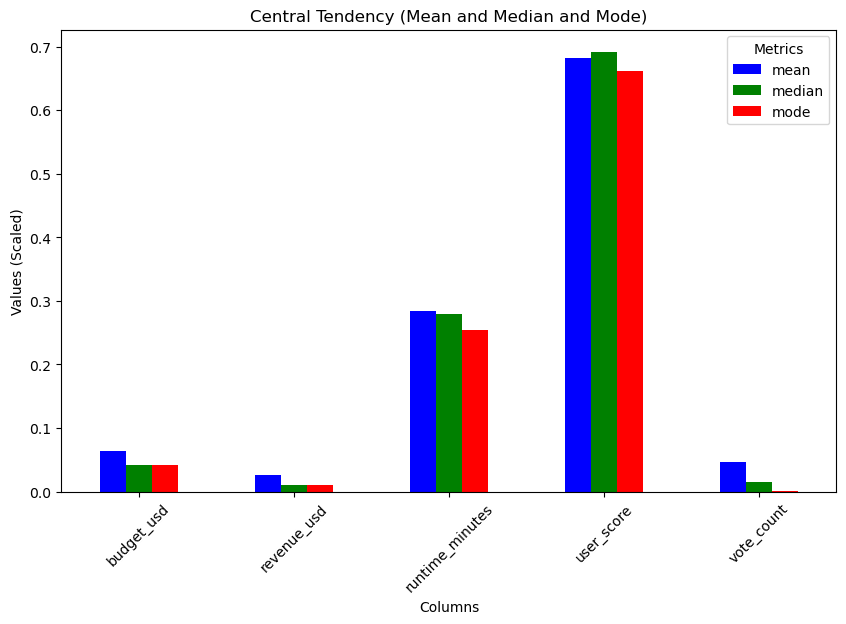


Visualizing Spread...


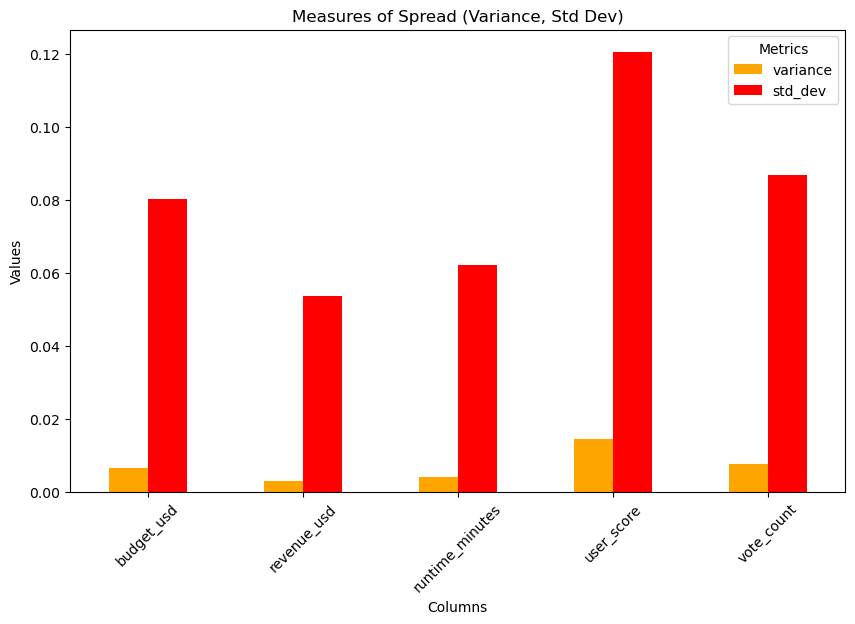


Visualizing IQR...


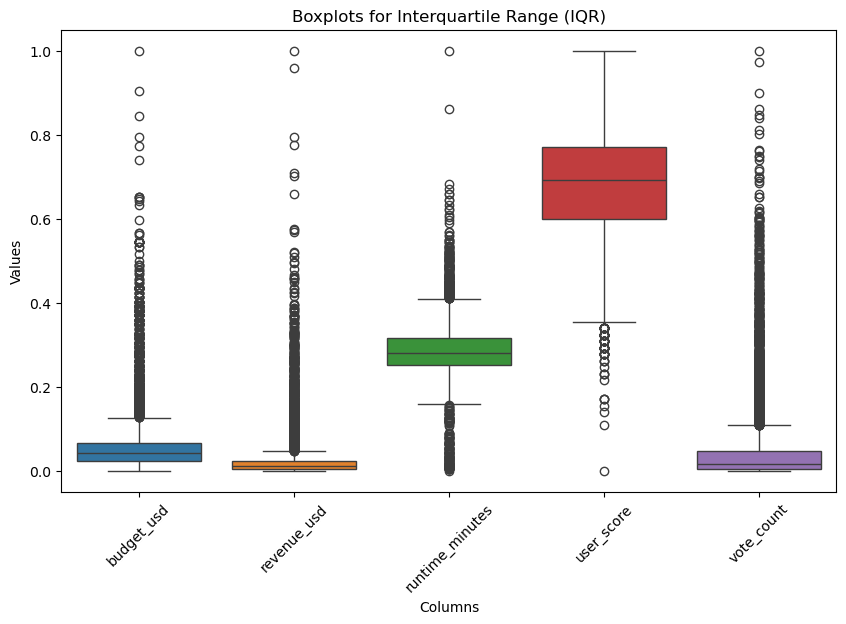


Visualizing Distribution...


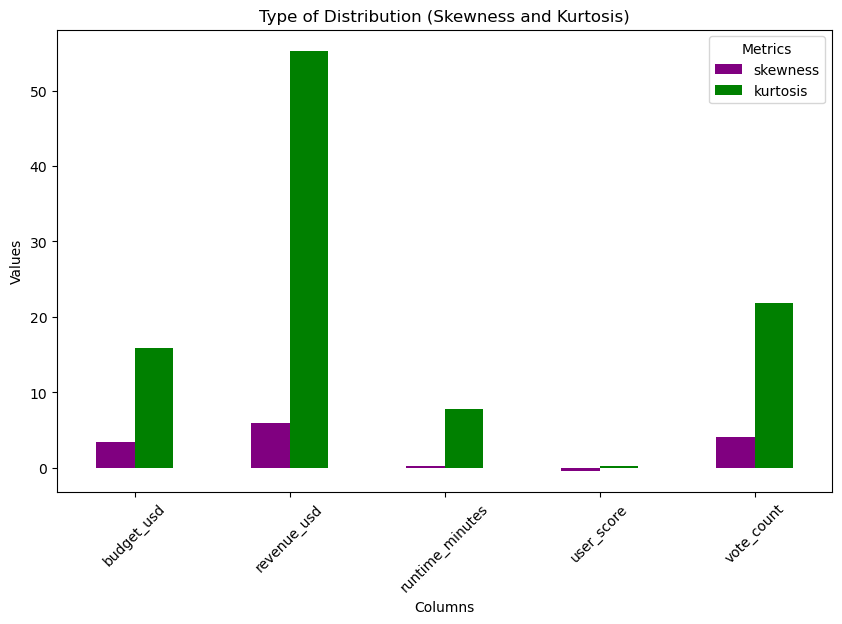

In [19]:
def visualize_statistical_analysis(central_tendency_summary, spread_summary, distribution_summary):
    # Visualize Central Tendency
    print("Visualizing Central Tendency...")
    visualize_central_tendency(central_tendency_summary)

    # Visualize Spread
    print("\nVisualizing Spread...")
    visualize_spread(spread_summary)
    
    print("\nVisualizing IQR...")
    visualize_iqr(processed_data,columns_to_analyze)

    # Visualize Distribution
    print("\nVisualizing Distribution...")
    visualize_distribution(distribution_summary)
    
# Call the combined visualization function
visualize_statistical_analysis(central_tendency_summary, spread_summary, distribution_summary)


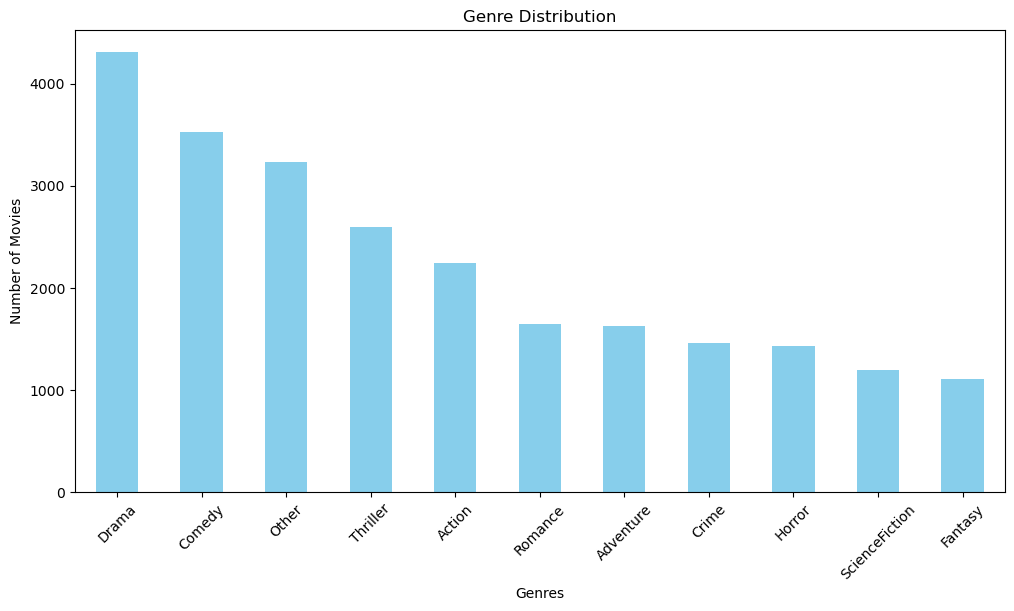

In [20]:
def plot_genre_distribution(df):
    genre_columns = ['Action', 'Adventure', 'Comedy', 'Crime', 'Drama', 
                     'Fantasy', 'Horror', 'Romance', 'ScienceFiction', 'Thriller', 'Other']
    
    genre_counts = df[genre_columns].sum().sort_values(ascending=False)
    plt.figure(figsize=(12, 6))
    genre_counts.plot(kind='bar', color='skyblue')
    plt.title('Genre Distribution')
    plt.xlabel('Genres')
    plt.ylabel('Number of Movies')
    plt.xticks(rotation=45)
    plt.show()

# Call the function
plot_genre_distribution(processed_data)


### Correlation Matrix

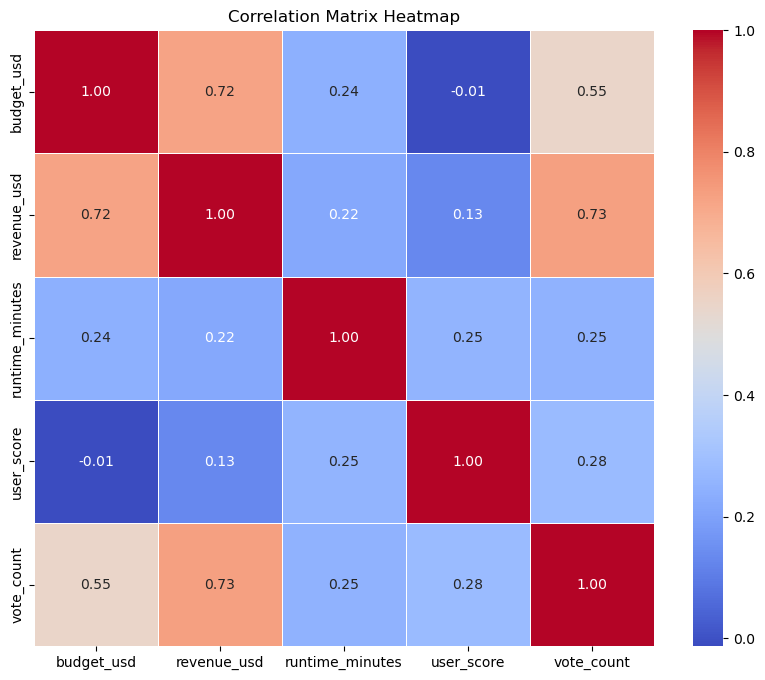

In [21]:
def analyze_correlation_matrix(df, columns):
    # Compute the correlation matrix
    corr_matrix = df[columns].corr()
    
    # Plot the heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
    plt.title('Correlation Matrix Heatmap')
    plt.show()

# Call the function
analyze_correlation_matrix(processed_data, columns_to_analyze)

### Observations

- `revenue_usd` is most strongly correlated with `vote_count` (0.73) and `budget_usd` (0.72). `runtime_minutes` (0.22) and `user_score` (0.13) are only weakly related to it.
- `budget_usd`, `revenue_usd` and `vote_count` are heavily right-skewed (skewness 3.4, 5.9 and 4.0, with very long tails), so a small number of blockbusters dominate. `runtime_minutes` and `user_score` are roughly symmetric.
- The median and mode of `budget_usd` and `revenue_usd` coincide because the missing values were filled with the median.

## Regression Models

**Features:** every numeric column except the target: budget, runtime, user score, vote count and the genre and language indicator columns. **Target:** `revenue_usd`.

1. **Linear regression** on an 80/20 train/test split, validated with 5-fold cross-validation.
2. **Polynomial regression** (degree 2) to capture interactions between the features and curvature.

In [22]:
def prepare_data(df, target_column):
    # Select numeric features and target
    X = df.select_dtypes(include=['float64', 'int64','int32']).drop(columns=[target_column])  
    y = df[target_column]  

    # Split into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    return X_train, X_test, y_train, y_test, X.columns

In [23]:
def train_model(X_train, y_train):
    model = LinearRegression()
    model.fit(X_train, y_train)
    print("Model trained successfully!")
    return model

In [24]:
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print("Model Evaluation:")
    print("Mean Squared Error (MSE):", mse)
    print("R-squared (R2):", r2)

    return mse, r2


In [25]:
def validate_model(model, X, y, cv=5):
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring='r2')
    print("Cross-Validation R2 Scores:", cv_scores)
    print("Mean Cross-Validation R2 Score:", cv_scores.mean())
    return cv_scores


In [26]:
# Prepare the data
X_train, X_test, y_train, y_test, feature_names = prepare_data(processed_data, target_column='revenue_usd')

# Train the model
model = train_model(X_train, y_train)

# Evaluate the model
mse, r2 = evaluate_model(model, X_test, y_test)

# Validate the model with cross-validation
cv_scores = validate_model(model, pd.concat([X_train, X_test]), pd.concat([y_train, y_test]))


Model trained successfully!
Model Evaluation:
Mean Squared Error (MSE): 0.0008413328374481376
R-squared (R2): 0.6806020748991076
Cross-Validation R2 Scores: [0.68971871 0.66965154 0.68623388 0.69335407 0.68071047]
Mean Cross-Validation R2 Score: 0.6839337320720649


In [27]:
def polynomial_regression_analysis(X_train, X_test, y_train, y_test, degree=2):
    # Create polynomial features
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    feature_names = poly.get_feature_names_out(X_train.columns)
    
    
    # Train the model
    model_poly = LinearRegression()
    model_poly.fit(X_train_poly, y_train)
    
    # Predictions and evaluation
    y_pred_poly = model_poly.predict(X_test_poly)
    mse_poly = mean_squared_error(y_test, y_pred_poly)
    r2_poly = r2_score(y_test, y_pred_poly)
    
    print("\nPolynomial Regression Results:")
    print("Mean Squared Error (MSE):", mse_poly)
    print("R-squared (R2):", r2_poly)
    
    return model_poly,  mse_poly, r2_poly

# Example usage
model_poly,  mse_poly, r2_poly = polynomial_regression_analysis(
    X_train, X_test, y_train, y_test, degree=2
)



Polynomial Regression Results:
Mean Squared Error (MSE): 0.0006993644323724116
R-squared (R2): 0.7344980028752519


## Results

,Model,MSE,R²
0,Linear regression,0.0008,0.6806
1,Polynomial regression (degree 2),0.0007,0.7345


Linear regression, mean 5-fold cross-validation R²: 0.684


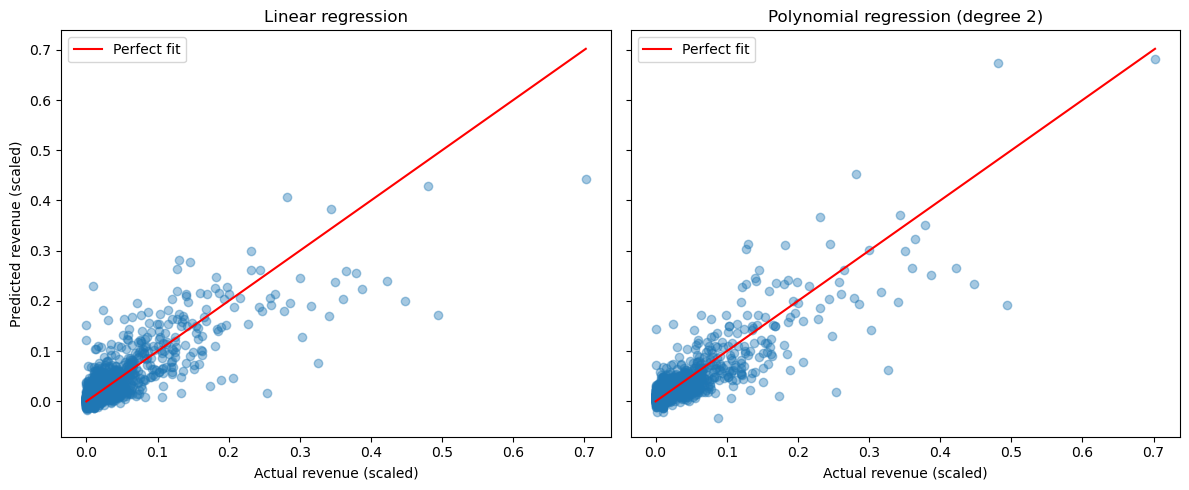

In [28]:
poly = PolynomialFeatures(degree=2, include_bias=False).fit(X_train)
y_pred_linear = model.predict(X_test)
y_pred_poly = model_poly.predict(poly.transform(X_test))

results = pd.DataFrame({
    "Model": ["Linear regression", "Polynomial regression (degree 2)"],
    "MSE": [mse, mse_poly],
    "R²": [r2, r2_poly],
}).round(4)
display(results)
print(f"Linear regression, mean 5-fold cross-validation R²: {cv_scores.mean():.3f}")

# Actual vs predicted revenue on the test set (values are Min-Max scaled)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, pred, name in zip(axes, [y_pred_linear, y_pred_poly], ["Linear regression", "Polynomial regression (degree 2)"]):
    ax.scatter(y_test, pred, alpha=0.4)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", label="Perfect fit")
    ax.set_title(name)
    ax.set_xlabel("Actual revenue (scaled)")
    ax.legend()
axes[0].set_ylabel("Predicted revenue (scaled)")
plt.tight_layout()
plt.show()

## Conclusion

- **Linear regression** explains about **68%** of the variance in revenue on the test set (R² 0.681), and the 5-fold cross-validated R² is almost the same (0.684), so the result is stable across splits.
- **Polynomial regression** (degree 2) raises the test R² to about **73%** (0.734), so some of the relationship is non-linear.
- **Budget** and **vote count** are by far the strongest predictors. User score and runtime add little.
- Both models underestimate the biggest earners, as the scatter plots show: revenue is so skewed that a few blockbusters are hard to predict from these features.

**Limitations**

- Budget and revenue are missing for about 31% and 26% of the movies. Those values were filled with the median, so they carry no real information, and the scores above include those rows.
- `vote_count` is only known after a film has been released, so this is a model of a film's revenue given how people responded to it, not a forecast made before release.